# Join All CSV Data into One DataFrame

This notebook follows the integration approach in `feature_relations.ipynb`. It:

1. Reads all eight project CSV files.
2. Uses `train.csv` as the row-level base table.
3. Joins HDB block attributes by `BLOCK` and `STREET`.
4. Adds nearest-facility distances and facility counts for MRT stations, malls, and schools.
5. Joins monthly COE and stock-market aggregates by approval year and month.

`test.csv` is loaded for completeness, but it is not merged into the training table because it has no `MONTHLY_RENT` target and represents a separate prediction set.

**Executed result:** Optuna-tuned LightGBM reached validation RMSE **478.603**. The best run used 18 leaves, 938 boosting iterations, learning rate 0.0369, depth 4, minimum split gain 0.7165, and 30 rows per leaf. This notebook used an earlier fixed holdout rather than the later standardized P1 chronological protocol, so the score is retained as historical evidence rather than used to rank the final models.

In [19]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from scipy.spatial import cKDTree

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1200)

In [20]:
import sys

# Find preprocessing.py whether the notebook is run from the project root,
# its own folder, or a remote Colab copy of the project.
module_dirs = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    module_dirs.extend([parent, parent / 'exploration' / 'metul'])
for root in [Path('/content'), Path('/content/drive/MyDrive')]:
    module_dirs.extend([root, root / 'KDDM-project', root / 'KDDM-project' / 'exploration' / 'metul'])
    if root.exists():
        try:
            module_dirs.extend(path.parent for path in root.rglob('preprocessing.py'))
        except (OSError, PermissionError):
            pass

for module_dir in module_dirs:
    if (module_dir / 'preprocessing.py').exists():
        sys.path.insert(0, str(module_dir))
        break

import importlib
import preprocessing
importlib.reload(preprocessing)
from preprocessing import load_datasets, preprocess_frame

data_dir, datasets = load_datasets()
train_df = datasets['train']
test_df = datasets['test']
coe_df = datasets['coe']
hdb_df = datasets['hdb']
mrt_df = datasets['mrt']
schools_df = datasets['schools']
malls_df = datasets['malls']
stock_df = datasets['stock']

aux_dir = data_dir / 'auxiliary'
print(f'Data directory: {data_dir.resolve()}')
print(f'An auxiliary directory: {aux_dir.resolve()}')

Data directory: /Users/metul/Desktop/KDDM-project/data
An auxiliary directory: /Users/metul/Desktop/KDDM-project/data/auxiliary


In [21]:
display(pd.DataFrame([
    {'dataset': name, 'rows': len(frame), 'columns': len(frame.columns)}
    for name, frame in datasets.items()
]))

,dataset,rows,columns
0,train,150000,11
1,test,50000,10
2,coe,539,8
3,hdb,9464,11
4,mrt,243,8
5,schools,337,14
6,malls,113,3
7,stock,91642,9


## Build the joined dataframe

The joins below are aggregated before merging so that each operation preserves one row per rental record.

In [25]:
# All train/test feature engineering is handled by preprocessing.py.
joined_df = preprocess_frame(train_df, datasets)
test_joined = preprocess_frame(test_df, datasets)
print(f'Joined training shape: {joined_df.shape}')
print(f'Joined test shape: {test_joined.shape}')
display(joined_df.head())

Joined training shape: (150000, 33)
Joined test shape: (50000, 32)


,RENT_APPROVAL_DATE,TOWN,BLOCK,STREET,FLAT_TYPE,FLAT_MODEL,FLOOR_AREA_SQM,FURNISHED,LEASE_COMMENCE_DATE,FEE,MONTHLY_RENT,approval_year,approval_month,approval_date_num,lease_age,flat_type_num,LATITUDE,LONGITUDE,MAX_FLOOR,YEAR_COMPLETED,mrt_dist_nearest_km,mrt_within_1km,mrt_within_2km,mall_dist_nearest_km,mall_within_1km,mall_within_2km,school_dist_nearest_km,school_within_1km,school_within_2km,coe_quota_premium_mean,coe_bids_mean,stock_close_mean,stock_volume_mean
0,2021-01,punggol,604a,punggol road,4 room,model a,93.0,yes,2012,0.0,1800,2021,1,24253,9,4,1.404310,103.907413,16,2010,0.555635,3,8,0.650683,2,7,0.267031,9,21,45187.375,1017.0,11.662779,6.403906e+06
1,2021-01,sengkang,290c,compassvale crescent,5 room,improved,110.0,yes,2001,0.0,2000,2021,1,24253,20,5,1.397018,103.897535,15,2000,0.633253,2,6,0.615214,1,6,0.274412,9,28,45187.375,1017.0,11.662779,6.403906e+06
2,2021-01,queenstown,5,ghim moh road,3 room,improved,65.0,yes,1976,0.0,2000,2021,1,24253,45,3,1.312693,103.788309,15,1975,0.624787,3,6,0.603773,3,3,0.627506,1,8,45187.375,1017.0,11.662779,6.403906e+06
3,2021-01,sengkang,436b,fernvale road,4 room,model a,96.0,yes,2010,0.0,1400,2021,1,24253,11,4,1.392878,103.876976,21,2008,2.066014,0,0,0.182555,1,2,0.195137,4,12,45187.375,1017.0,11.662779,6.403906e+06
4,2021-01,sembawang,467b,admiralty drive,4 room,premium apartment,102.0,yes,2001,0.0,1800,2021,1,24253,20,4,1.451141,103.813630,16,1999,0.760948,1,3,0.729008,1,2,0.236268,6,12,45187.375,1017.0,11.662779,6.403906e+06


## Correlation with the target

The following cells calculate Pearson correlation between `MONTHLY_RENT` and every varying numeric feature in `joined_df`. The proximity features are then displayed separately for easier interpretation.

In [26]:
numeric_columns = joined_df.select_dtypes(include=np.number).columns.tolist()
varying_columns = [
    column for column in numeric_columns
    if joined_df[column].nunique(dropna=True) > 1
]

correlation_with_target = (
    joined_df[varying_columns]
    .corr()['MONTHLY_RENT']
    .drop('MONTHLY_RENT')
    .sort_values(ascending=False)
)

correlation_table = pd.DataFrame({
    'feature': correlation_with_target.index,
    'correlation_with_monthly_rent': correlation_with_target.values,
    'absolute_correlation': correlation_with_target.abs().values,
}).sort_values('absolute_correlation', ascending=False).reset_index(drop=True)

display(correlation_table.style.format({
    'correlation_with_monthly_rent': '{:.4f}',
    'absolute_correlation': '{:.4f}',
}))

,feature,correlation_with_monthly_rent,absolute_correlation
0,approval_date_num,0.5346,0.5346
1,approval_year,0.5172,0.5172
2,coe_quota_premium_mean,0.5113,0.5113
3,flat_type_num,0.3449,0.3449
4,FLOOR_AREA_SQM,0.3293,0.3293
5,MAX_FLOOR,0.2921,0.2921
6,LEASE_COMMENCE_DATE,0.2294,0.2294
7,stock_volume_mean,-0.2265,0.2265
8,lease_age,-0.1781,0.1781
9,LATITUDE,-0.1130,0.1130


Correlation of proximity features with MONTHLY_RENT:


,feature,correlation_with_monthly_rent,absolute_correlation
12,mrt_dist_nearest_km,-0.084663,0.084663
13,mall_dist_nearest_km,-0.083036,0.083036
18,school_within_2km,-0.034543,0.034543
19,school_within_1km,-0.029398,0.029398
23,school_dist_nearest_km,-0.001079,0.001079
17,mall_within_1km,0.060620,0.060620
15,mall_within_2km,0.063368,0.063368
11,mrt_within_1km,0.086867,0.086867
10,mrt_within_2km,0.099504,0.099504


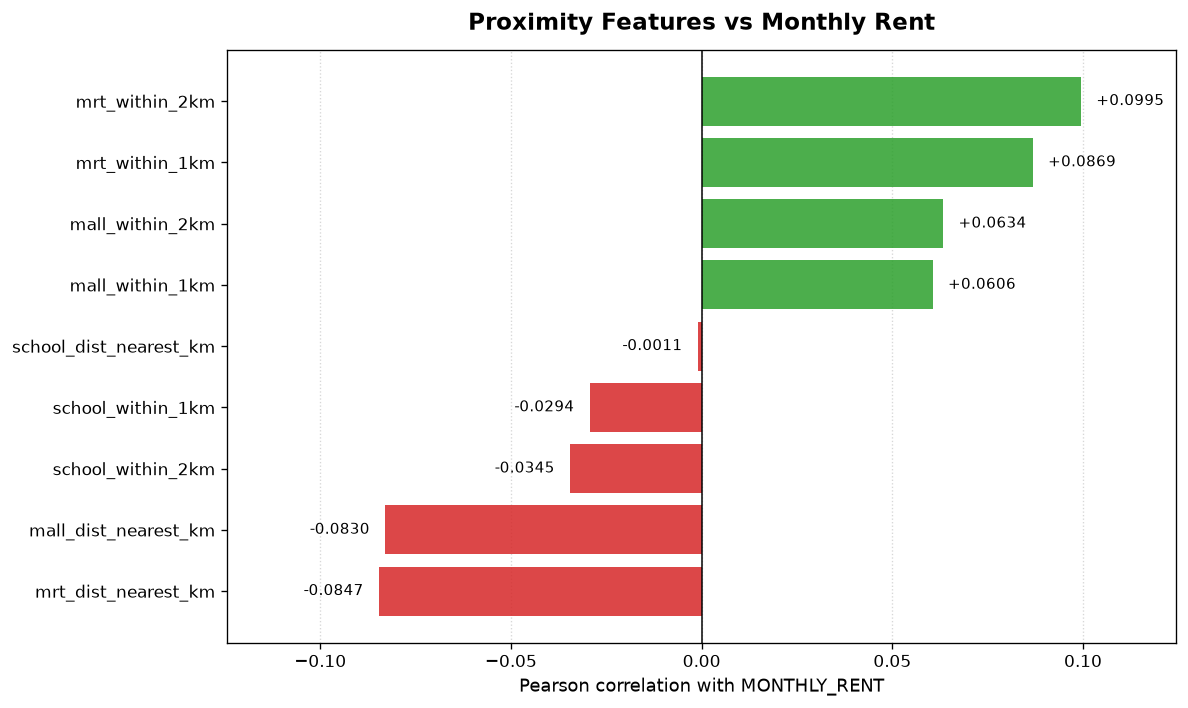

In [27]:
proximity_features = [
    column for column in correlation_table['feature']
    if column.startswith(('mrt_', 'mall_', 'school_'))
]

proximity_correlation_table = correlation_table[
    correlation_table['feature'].isin(proximity_features)
].sort_values('correlation_with_monthly_rent')

print('Correlation of proximity features with MONTHLY_RENT:')
display(proximity_correlation_table)

# Neat horizontal bar chart of proximity correlations.
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)
values = proximity_correlation_table['correlation_with_monthly_rent'].to_numpy()
labels = proximity_correlation_table['feature'].to_numpy()
colors = ['#2ca02c' if value >= 0 else '#d62728' for value in values]
bars = ax.barh(labels, values, color=colors, alpha=0.85)
ax.axvline(0, color='black', linewidth=0.9)
ax.set_title('Proximity Features vs Monthly Rent', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Pearson correlation with MONTHLY_RENT', fontsize=11)
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)

max_abs = max(abs(values).max(), 0.01)
ax.set_xlim(-max_abs * 1.25, max_abs * 1.25)
for bar, value in zip(bars, values):
    offset = max_abs * 0.04 if value >= 0 else -max_abs * 0.04
    ax.text(
        value + offset, bar.get_y() + bar.get_height() / 2,
        f'{value:+.4f}', va='center',
        ha='left' if value >= 0 else 'right', fontsize=9
    )

plt.tight_layout()
plt.show()

In [28]:
# Final checks: one row per training record and missing values by column.
print(f'Rows preserved from train.csv: {len(joined_df) == len(train_df)}')
print(f'Columns in joined dataframe: {len(joined_df.columns)}')
display(joined_df.isna().sum().loc[lambda values: values.gt(0)].to_frame('missing_values'))

Rows preserved from train.csv: True
Columns in joined dataframe: 33


,missing_values


## All-feature LightGBM model and feature importance

The model uses all joined modeling features. The target is excluded, along with the raw approval-date string and constant/non-informative columns. Text columns are converted to pandas `category` dtype so LightGBM can use them as categorical features.

In [29]:
excluded_columns = ['MONTHLY_RENT', 'RENT_APPROVAL_DATE', 'FEE', 'FURNISHED']
feature_columns = [column for column in joined_df.columns if column not in excluded_columns]
X_all = joined_df[feature_columns].copy()
y = joined_df['MONTHLY_RENT']

categorical_columns = X_all.select_dtypes(include=['object', 'string']).columns.tolist()
for column in categorical_columns:
    X_all[column] = X_all[column].astype('category')

print(f'Features used: {len(feature_columns)}')
print(f'Categorical features: {categorical_columns}')


Features used: 29
Categorical features: ['TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL']


In [30]:
model = lgb.LGBMRegressor(
)

model.fit(X_all, y, categorical_feature=categorical_columns)

feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'split_importance': model.booster_.feature_importance(importance_type='split'),
    'gain_importance': model.booster_.feature_importance(importance_type='gain'),
}).sort_values('gain_importance', ascending=False).reset_index(drop=True)

feature_importance['gain_importance_pct'] = (
    100 * feature_importance['gain_importance'] / feature_importance['gain_importance'].sum()
)

print('All-feature LightGBM feature importance:')
display(feature_importance.style.format({
    'split_importance': '{:,.0f}',
    'gain_importance': '{:,.2f}',
    'gain_importance_pct': '{:.2f}%',
}))

All-feature LightGBM feature importance:


,feature,split_importance,gain_importance,gain_importance_pct
0,approval_date_num,140,"137,474,804,080.00",47.41%
1,flat_type_num,71,"51,990,113,610.00",17.93%
2,STREET,863,"21,049,045,890.00",7.26%
3,BLOCK,"1,308","19,946,092,702.00",6.88%
4,TOWN,85,"19,158,523,900.00",6.61%
5,FLAT_TYPE,64,"14,149,777,728.00",4.88%
6,FLOOR_AREA_SQM,81,"7,417,275,842.00",2.56%
7,LATITUDE,35,"6,145,282,416.00",2.12%
8,LEASE_COMMENCE_DATE,30,"3,685,901,828.00",1.27%
9,MAX_FLOOR,24,"2,369,609,906.00",0.82%


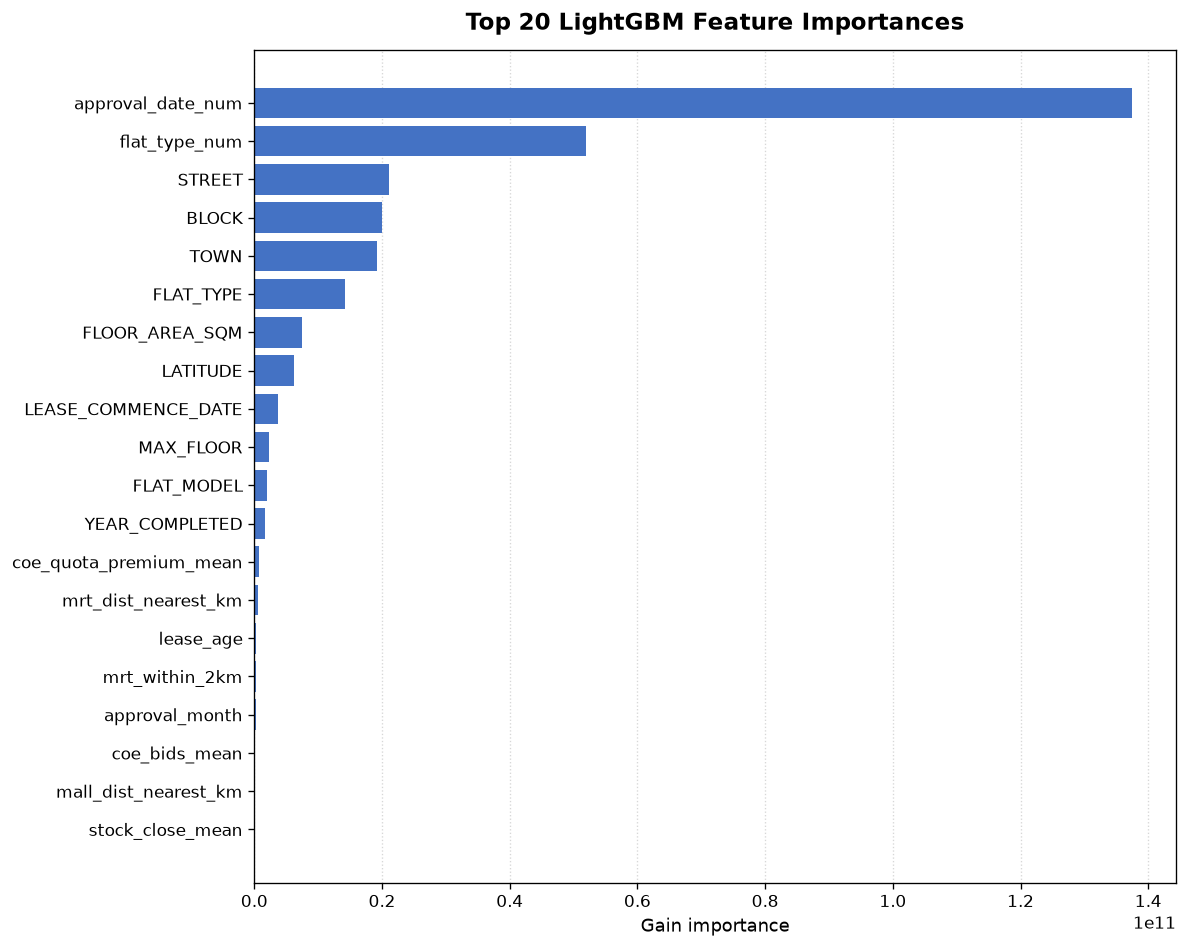

In [31]:
# Plot the 20 most important features by gain.
top_importance = feature_importance.head(20).sort_values('gain_importance')
fig, ax = plt.subplots(figsize=(10, 8), dpi=120)
ax.barh(top_importance['feature'], top_importance['gain_importance'], color='#4472C4')
ax.set_title('Top 20 LightGBM Feature Importances', fontsize=14, fontweight='bold', pad=12)
ax.set_xlabel('Gain importance', fontsize=11)
ax.grid(axis='x', linestyle=':', alpha=0.5)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## Five-trial Optuna hyperparameter search

This searches practical LightGBM ranges for `num_leaves`, `num_iterations`, `learning_rate`, `max_depth`, `min_gain_to_split`, and `min_data_in_leaf`. RMSE on a fixed 20% validation split is minimized.

In [32]:
import optuna
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X_train, X_valid, y_train, y_valid = train_test_split(
    X_all, y, test_size=0.20, random_state=42
)

def objective(trial):
    params = {
        'objective': 'regression',
        'metric': 'rmse',
        'num_leaves': trial.suggest_int('num_leaves', 16, 500),
        'num_iterations': trial.suggest_int('num_iterations', 200, 1500),
        'learning_rate': trial.suggest_float('learning_rate', 0.01, 0.20, log=True),
        'max_depth': trial.suggest_int('max_depth', 3, 15),
        'min_gain_to_split': trial.suggest_float('min_gain_to_split', 0.0, 1.0),
        'min_data_in_leaf': trial.suggest_int('min_data_in_leaf', 20, 200),
        'random_state': 42, 'verbosity': -1, 'n_jobs': -1,
    }
    trial_model = lgb.LGBMRegressor(**params)
    trial_model.fit(
        X_train, y_train, eval_set=[(X_valid, y_valid)],
        categorical_feature=categorical_columns,
        callbacks=[lgb.early_stopping(50, verbose=False)],
    )
    predictions = trial_model.predict(X_valid, num_iteration=trial_model.best_iteration_)
    rmse = mean_squared_error(y_valid, predictions) ** 0.5
    print(f'Trial {trial.number + 1}: RMSE={rmse:.2f}')
    return rmse

study = optuna.create_study(
    direction='minimize', sampler=optuna.samplers.TPESampler(seed=42)
)
study.optimize(objective, n_trials=50)
best_params = study.best_params
print(f'Best validation RMSE: {study.best_value:.2f}')
best_params_output = pd.DataFrame([{
    **best_params,
    'best_validation_rmse': study.best_value,
    'feature_count': X_all.shape[1],
}])
best_params_output.to_csv('exp_2_best_params.csv', index=False)
display(best_params_output)
print('Saved exp_2_best_params.csv')

[I 2026-09-14 11:22:48,478] A new study created in memory with name: no-name-67e444d1-8e0a-451b-bf4a-9d64e4564633
/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-09-14 11:22:50,678] Trial 0 finished with value: 482.05763281017784 and parameters: {'num_leaves': 197, 'num_iterations': 1436, 'learning_rate': 0.08960785365368121, 'max_depth': 10, 'min_gain_to_split': 0.15601864044243652, 'min_data_in_leaf': 48}. Best is trial 0 with value: 482.05763281017784.


Trial 1: RMSE=482.06


/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-09-14 11:22:52,352] Trial 1 finished with value: 480.6825503619632 and parameters: {'num_leaves': 44, 'num_iterations': 1326, 'learning_rate': 0.06054365855469249, 'max_depth': 12, 'min_gain_to_split': 0.020584494295802447, 'min_data_in_leaf': 195}. Best is trial 1 with value: 480.6825503619632.


Trial 2: RMSE=480.68


/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-09-14 11:22:54,745] Trial 2 finished with value: 479.44579239756865 and parameters: {'num_leaves': 419, 'num_iterations': 476, 'learning_rate': 0.017240892195821537, 'max_depth': 5, 'min_gain_to_split': 0.3042422429595377, 'min_data_in_leaf': 114}. Best is trial 2 with value: 479.44579239756865.


...

/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-09-14 11:24:56,916] Trial 48 finished with value: 478.96360479051043 and parameters: {'num_leaves': 40, 'num_iterations': 1148, 'learning_rate': 0.03517703879314702, 'max_depth': 6, 'min_gain_to_split': 0.4262287546847862, 'min_data_in_leaf': 45}. Best is trial 31 with value: 478.6029705504875.


Trial 49: RMSE=478.96


/Users/metul/Desktop/KDDM-project/venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)
[I 2026-09-14 11:24:58,637] Trial 49 finished with value: 479.11305473394515 and parameters: {'num_leaves': 74, 'num_iterations': 777, 'learning_rate': 0.027485031609452128, 'max_depth': 3, 'min_gain_to_split': 0.10352905513514932, 'min_data_in_leaf': 37}. Best is trial 31 with value: 478.6029705504875.


Trial 50: RMSE=479.11
Best validation RMSE: 478.60


,num_leaves,num_iterations,learning_rate,max_depth,min_gain_to_split,min_data_in_leaf
0,18,938,0.036935,4,0.716468,30


In [33]:
# Feature importance from a model trained with the best HPT parameters.
best_model = lgb.LGBMRegressor(
    **best_params, objective='regression', random_state=42,
    importance_type='gain', verbosity=-1, n_jobs=-1
)
best_model.fit(X_all, y, categorical_feature=categorical_columns)
hpt_feature_importance = pd.DataFrame({
    'feature': feature_columns,
    'gain_importance': best_model.booster_.feature_importance(importance_type='gain'),
    'split_importance': best_model.booster_.feature_importance(importance_type='split'),
}).sort_values('gain_importance', ascending=False).reset_index(drop=True)
hpt_feature_importance['gain_importance_pct'] = (
    100 * hpt_feature_importance['gain_importance']
    / hpt_feature_importance['gain_importance'].sum()
)
display(hpt_feature_importance.head(20).style.format({
    'gain_importance': '{:,.2f}', 'split_importance': '{:,.0f}',
    'gain_importance_pct': '{:.2f}%',
}))

,feature,gain_importance,split_importance,gain_importance_pct
0,approval_date_num,"357,821,108,147.00",979,47.40%
1,flat_type_num,"121,572,537,173.00",170,16.10%
2,TOWN,"54,552,667,481.00",375,7.23%
3,STREET,"48,493,623,484.00","2,448",6.42%
4,FLAT_TYPE,"48,374,620,253.00",356,6.41%
5,BLOCK,"42,992,558,553.00","3,644",5.70%
6,FLOOR_AREA_SQM,"25,709,664,548.00",541,3.41%
7,LATITUDE,"12,364,117,756.00",169,1.64%
8,MAX_FLOOR,"11,749,114,955.00",151,1.56%
9,LEASE_COMMENCE_DATE,"6,853,892,807.00",134,0.91%


In [34]:
# Final checks: one row per training record and missing values by column.
print(f'Rows preserved from train.csv: {len(joined_df) == len(train_df)}')
print(f'Columns in joined dataframe: {len(joined_df.columns)}')
display(joined_df.isna().sum().loc[lambda values: values.gt(0)].to_frame('missing_values'))

Rows preserved from train.csv: True
Columns in joined dataframe: 33


,missing_values


In [35]:

# Separate target from features
target = "MONTHLY_RENT"

excluded_columns = [
    target,
    "RENT_APPROVAL_DATE",
    "FEE",
    "FURNISHED",
]

feature_columns = [
    column for column in joined_df.columns
    if column not in excluded_columns
]

X = joined_df[feature_columns].copy()
y = joined_df[target]

# Convert text columns to categorical features
categorical_columns = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

for column in categorical_columns:
    X[column] = X[column].astype("category")

# Load the Optuna-best parameters created by the HPT cell.
param_columns = [
    'num_leaves', 'num_iterations', 'learning_rate',
    'max_depth', 'min_gain_to_split', 'min_data_in_leaf',
]
best_params_file = Path('exp_2_best_params.csv')
if not best_params_file.exists():
    raise FileNotFoundError('Run the Optuna HPT cell first to create exp_2_best_params.csv.')
best_params_row = pd.read_csv(best_params_file).iloc[0]
best_params = {column: best_params_row[column] for column in param_columns}
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['num_iterations'] = int(best_params['num_iterations'])
best_params['max_depth'] = int(best_params['max_depth'])
best_params['min_data_in_leaf'] = int(best_params['min_data_in_leaf'])

# Train on the complete training dataset
model = lgb.LGBMRegressor(
    objective="regression",
    random_state=42,
    importance_type="gain",
    verbosity=-1,
    n_jobs=-1,
    **best_params,
)

model.fit(
    X,
    y,
    categorical_feature=categorical_columns,
)

print("Model trained on complete training data.")
print(f"Rows used: {len(X):,}")
print(f"Features used: {len(feature_columns)}")

# Feature importance
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "gain_importance": model.booster_.feature_importance(
        importance_type="gain"
    ),
    "split_importance": model.booster_.feature_importance(
        importance_type="split"
    ),
}).sort_values(
    "gain_importance",
    ascending=False
).reset_index(drop=True)

feature_importance["gain_importance_pct"] = (
    feature_importance["gain_importance"]
    / feature_importance["gain_importance"].sum()
    * 100
)

display(
    feature_importance.style.format({
        "gain_importance": "{:,.2f}",
        "split_importance": "{:,.0f}",
        "gain_importance_pct": "{:.2f}%",
    })
)

Model trained on complete training data.
Rows used: 150,000
Features used: 29


,feature,gain_importance,split_importance,gain_importance_pct
0,approval_date_num,"357,798,908,386.00","1,004",47.41%
1,flat_type_num,"121,578,438,971.00",170,16.11%
2,TOWN,"54,544,915,611.00",380,7.23%
3,FLAT_TYPE,"48,417,454,045.00",367,6.42%
4,STREET,"48,306,535,570.00","2,411",6.40%
5,BLOCK,"43,079,646,007.00","3,652",5.71%
6,FLOOR_AREA_SQM,"25,744,558,015.00",572,3.41%
7,LATITUDE,"12,395,988,125.60",184,1.64%
8,MAX_FLOOR,"11,709,504,581.00",140,1.55%
9,LEASE_COMMENCE_DATE,"6,798,564,950.00",121,0.90%


In [37]:
# Prepare the already-preprocessed test data and generate predictions.
target = 'MONTHLY_RENT'
excluded_columns = [target, 'RENT_APPROVAL_DATE', 'FEE', 'FURNISHED']
feature_columns = [column for column in joined_df.columns if column not in excluded_columns]
X = joined_df[feature_columns].copy()
y = joined_df[target]
categorical_columns = X.select_dtypes(include=['object', 'string']).columns.tolist()
for column in categorical_columns:
    X[column] = X[column].astype('category')

param_columns = [
    'num_leaves', 'num_iterations', 'learning_rate',
    'max_depth', 'min_gain_to_split', 'min_data_in_leaf',
]
best_params_file = Path('exp_2_best_params.csv')
if not best_params_file.exists():
    raise FileNotFoundError('Run the Optuna HPT cell first to create exp_2_best_params.csv.')
best_params_row = pd.read_csv(best_params_file).iloc[0]
best_params = {column: best_params_row[column] for column in param_columns}
best_params['num_leaves'] = int(best_params['num_leaves'])
best_params['num_iterations'] = int(best_params['num_iterations'])
best_params['max_depth'] = int(best_params['max_depth'])
best_params['min_data_in_leaf'] = int(best_params['min_data_in_leaf'])
model = lgb.LGBMRegressor(
    objective='regression', random_state=42, importance_type='gain',
    verbosity=-1, n_jobs=-1, **best_params
)
model.fit(X, y, categorical_feature=categorical_columns)

X_test = test_joined.reindex(columns=feature_columns).copy()
for column in categorical_columns:
    X_test[column] = X_test[column].astype(
        pd.api.types.CategoricalDtype(categories=X[column].cat.categories)
    )

predictions = model.predict(X_test).round().astype(int)
submission = pd.DataFrame({'Id': test_df.index, 'Predicted': predictions})
submission.to_csv('test_predictions.csv', index=False)
print('Created test_predictions.csv')
display(submission.head())

Created test_predictions.csv


/var/folders/xd/2yk04_yn3ls3kqgyz397mjyh0000gn/T/ipykernel_16066/219591686.py:23: Pandas4Warning: Constructing a Categorical with a dtype and values containing non-null entries not in that dtype's categories is deprecated and will raise in a future version.
  X_test[column] = X_test[column].astype(


,Id,Predicted
0,0,2781
1,1,3640
2,2,3096
3,3,3123
4,4,3319
